In [1]:
import os
import re
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Library berhasil di-import.")

Library berhasil di-import.


In [2]:
CSV_PATH = "20191002-reviews.csv"

# Jika nama file berbeda, ubah CSV_PATH sesuai nama file kamu.
print("CSV_PATH =", CSV_PATH)

# Load dataset
df = pd.read_csv(CSV_PATH)

print("Shape:", df.shape)
display(df.head())

CSV_PATH = 20191002-reviews.csv
Shape: (203787, 15)


,itemId,category,name,rating,originalRating,reviewTitle,reviewContent,likeCount,upVotes,downVotes,helpful,relevanceScore,boughtDate,clientType,retrievedDate
0,100002528,beli-harddisk-eksternal,Kamal U.,5,NaN,NaN,bagus mantap dah sesui pesanan,0,0,0,True,26.51,09 Apr 2019,androidApp,2019-10-02
1,100002528,beli-harddisk-eksternal,yofanca m.,4,NaN,NaN,"Bagus, sesuai foto",0,0,0,True,22.49,24 Sep 2017,androidApp,2019-10-02
2,100002528,beli-harddisk-eksternal,Lazada Customer,5,NaN,ok mantaaapppp barang sesuai pesanan.. good,okkkkk mantaaaaaaapppp ... goood,0,0,0,True,21.50,04 Apr 2018,androidApp,2019-10-02
3,100002528,beli-harddisk-eksternal,Lazada Customer,4,NaN,NaN,bagus sesuai,0,0,0,True,20.51,22 Sep 2017,androidApp,2019-10-02
4,100002528,beli-harddisk-eksternal,Yosep M.,5,NaN,NaN,NaN,0,0,0,True,16.01,17 Agu 2018,androidApp,2019-10-02


In [3]:
print("Kolom dataset:")
print(df.columns.tolist())

print("\nInfo:")
df.info()


Kolom dataset:
['itemId', 'category', 'name', 'rating', 'originalRating', 'reviewTitle', 'reviewContent', 'likeCount', 'upVotes', 'downVotes', 'helpful', 'relevanceScore', 'boughtDate', 'clientType', 'retrievedDate']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 203787 entries, 0 to 203786
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   itemId          203787 non-null  int64  
 1   category        203787 non-null  object 
 2   name            203787 non-null  object 
 3   rating          203787 non-null  int64  
 4   originalRating  8 non-null       float64
 5   reviewTitle     23399 non-null   object 
 6   reviewContent   107029 non-null  object 
 7   likeCount       203787 non-null  int64  
 8   upVotes         203787 non-null  int64  
 9   downVotes       203787 non-null  int64  
 10  helpful         203787 non-null  bool   
 11  relevanceScore  203787 non-null  float64
 12  boughtDate      

In [4]:
# Cek missing values
missing = df.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0])

# Cek distribusi rating jika kolom tersedia
if "rating" in df.columns:
    display(df["rating"].value_counts().sort_index())


originalRating    203779
reviewTitle       180388
reviewContent      96758
boughtDate          7107
dtype: int64

rating
1      9749
2      3382
3      7073
4     17567
5    166016
Name: count, dtype: int64

In [5]:
# Pastikan kolom utama tersedia
required_columns = ["itemId", "rating"]

missing_required = [col for col in required_columns if col not in df.columns]

if missing_required:
    raise ValueError(
        f"Kolom wajib tidak ditemukan: {missing_required}. "
        f"Kolom yang tersedia: {df.columns.tolist()}"
    )

print("Kolom utama tersedia.")


Kolom utama tersedia.


In [6]:
# Ambil kolom yang diperlukan
data = df[["reviewContent", "rating"]].copy()

# Hapus missing
data = data.dropna(subset=["reviewContent", "rating"])

# Pastikan rating numerik
data["rating"] = pd.to_numeric(data["rating"], errors="coerce")
data = data.dropna(subset=["rating"])

# Binary labeling
data["sentiment"] = data["rating"].map(
    {1: "Negative", 2: "Negative", 4: "Positive", 5: "Positive"}
)

# Buang rating 3 dan rating lain yang tidak digunakan
data = data.dropna(subset=["sentiment"])

# Buang review kosong
data["reviewContent"] = data["reviewContent"].astype(str).str.strip()
data = data[data["reviewContent"].str.len() > 0]

# Hapus duplicate review
data = data.drop_duplicates(subset=["reviewContent"])

data = data.reset_index(drop=True)

print("Shape setelah cleaning:", data.shape)
display(data.head())


Shape setelah cleaning: (36479, 3)


,reviewContent,rating,sentiment
0,bagus mantap dah sesui pesanan,5,Positive
1,"Bagus, sesuai foto",4,Positive
2,okkkkk mantaaaaaaapppp ... goood,5,Positive
3,bagus sesuai,4,Positive
4,bima,1,Negative


sentiment
Positive    33032
Negative     3447
Name: count, dtype: int64

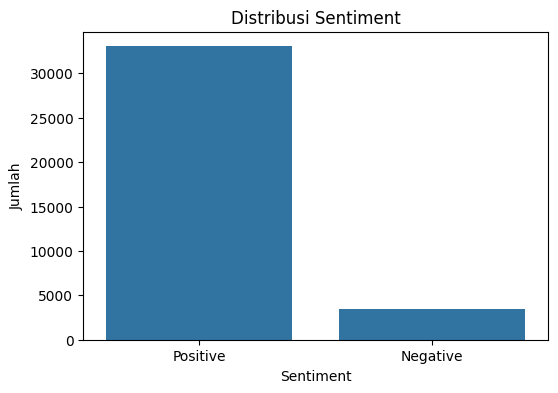

In [7]:
# Distribusi label
label_counts = data["sentiment"].value_counts()

display(label_counts)

plt.figure(figsize=(6, 4))
sns.countplot(data=data, x="sentiment")
plt.title("Distribusi Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Jumlah")
plt.show()


In [8]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-zA-ZÀ-ÿ0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


data["clean_text"] = data["reviewContent"].apply(clean_text)

display(data[["reviewContent", "clean_text", "sentiment"]].head(10))


,reviewContent,clean_text,sentiment
0,bagus mantap dah sesui pesanan,bagus mantap dah sesui pesanan,Positive
1,"Bagus, sesuai foto",bagus sesuai foto,Positive
2,okkkkk mantaaaaaaapppp ... goood,okkkkk mantaaaaaaapppp goood,Positive
3,bagus sesuai,bagus sesuai,Positive
4,bima,bima,Negative
5,baru 10 bulan layarnya dah bergaris,baru 10 bulan layarnya dah bergaris,Negative
6,"Pesan rabu sore,minggu sore sampe,,barang sesu...",pesan rabu sore minggu sore sampe barang sesua...,Positive
7,"Mau tanya ini cicilnya pake apa ya,cc bkn?",mau tanya ini cicilnya pake apa ya cc bkn,Negative
8,Apakah TV. Tsb. Suda ada anti gores..,apakah tv tsb suda ada anti gores,Positive
9,Pengirim barang tidak sesuai janji. Katanya ex...,pengirim barang tidak sesuai janji katanya exp...,Negative


In [9]:
# Cek apakah ada teks kosong setelah cleaning
empty_after_cleaning = (data["clean_text"].str.len() == 0).sum()
print("Empty text:", empty_after_cleaning)

data = data[data["clean_text"].str.len() > 0].reset_index(drop=True)

print("Final dataset:", data.shape)


Empty text: 51
Final dataset: (36428, 4)


In [10]:
X = data["clean_text"]
y = data["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

print("\nTrain distribution:")
display(y_train.value_counts(normalize=True))

print("\nTest distribution:")
display(y_test.value_counts(normalize=True))


Training: (29142,)
Testing : (7286,)

Train distribution:


sentiment
Positive    0.905497
Negative    0.094503
Name: proportion, dtype: float64


Test distribution:


sentiment
Positive    0.905435
Negative    0.094565
Name: proportion, dtype: float64

In [11]:
models = {
    "Logistic Regression": Pipeline(
        [
            (
                "tfidf",
                TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000),
            ),
            ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        ]
    ),
    "Naive Bayes": Pipeline(
        [
            (
                "tfidf",
                TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000),
            ),
            ("model", MultinomialNB()),
        ]
    ),
    "Linear SVM": Pipeline(
        [
            (
                "tfidf",
                TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000),
            ),
            ("model", LinearSVC(random_state=RANDOM_STATE)),
        ]
    ),
    "Random Forest": Pipeline(
        [
            (
                "tfidf",
                TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000),
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
                ),
            ),
        ]
    ),
}

print("Model siap:", list(models.keys()))

# for name, pipeline in models.items():
#     pipeline.fit(X_train, y_train)

# print("Semua model berhasil dilatih.")

Model siap: ['Logistic Regression', 'Naive Bayes', 'Linear SVM', 'Random Forest']


In [12]:
results = []

for name, pipeline in models.items():
    print(f"Training: {name}")

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    results.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, pos_label="Positive"),
            "Recall": recall_score(y_test, y_pred, pos_label="Positive"),
            "F1-Score": f1_score(y_test, y_pred, pos_label="Positive"),
        }
    )

results_df = (
    pd.DataFrame(results)
    .sort_values(by="F1-Score", ascending=False)
    .reset_index(drop=True)
)

display(results_df)


Training: Logistic Regression
Training: Naive Bayes
Training: Linear SVM
Training: Random Forest


,Model,Accuracy,Precision,Recall,F1-Score
0,Linear SVM,0.945100,0.960333,0.979839,0.969988
1,Logistic Regression,0.939885,0.947537,0.988328,0.967503
2,Random Forest,0.926709,0.930917,0.992724,0.960827
3,Naive Bayes,0.917101,0.918214,0.997271,0.956111


In [13]:
# Classification report untuk setiap model
for name, pipeline in models.items():
    y_pred = pipeline.predict(X_test)

    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(y_test, y_pred))


Logistic Regression
              precision    recall  f1-score   support

    Negative       0.81      0.48      0.60       689
    Positive       0.95      0.99      0.97      6597

    accuracy                           0.94      7286
   macro avg       0.88      0.73      0.78      7286
weighted avg       0.93      0.94      0.93      7286

Naive Bayes
              precision    recall  f1-score   support

    Negative       0.85      0.15      0.25       689
    Positive       0.92      1.00      0.96      6597

    accuracy                           0.92      7286
   macro avg       0.88      0.57      0.61      7286
weighted avg       0.91      0.92      0.89      7286

Linear SVM
              precision    recall  f1-score   support

    Negative       0.76      0.61      0.68       689
    Positive       0.96      0.98      0.97      6597

    accuracy                           0.95      7286
   macro avg       0.86      0.80      0.82      7286
weighted avg       0.94      0.

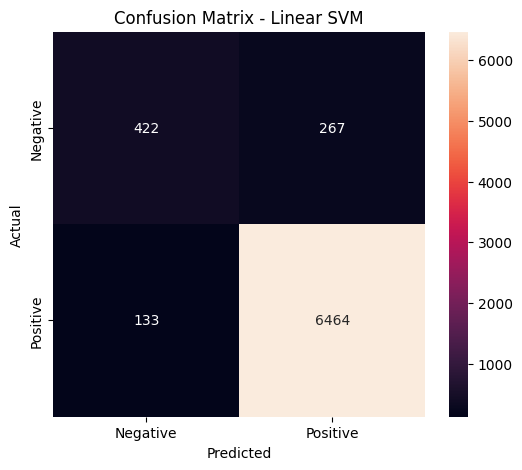

Best Model: Linear SVM


In [14]:
# Confusion matrix model terbaik berdasarkan F1
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

best_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_pred, labels=["Negative", "Positive"])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("Best Model:", best_model_name)


In [15]:
import mlflow
import mlflow.sklearn

MLFLOW_EXPERIMENT = "customer-feedback-classification"

mlflow.set_experiment(MLFLOW_EXPERIMENT)

print("MLflow experiment:", MLFLOW_EXPERIMENT)


2026/11/08 14:13:15 INFO mlflow.tracking.fluent: Experiment with name 'customer-feedback-classification' does not exist. Creating a new experiment.


MLflow experiment: customer-feedback-classification


In [16]:
# Jalankan ulang training sambil mencatat eksperimen ke MLflow.
# Jika MLflow server lokal belum dijalankan, MLflow akan menggunakan local tracking.

mlflow_runs = []

for name, pipeline in models.items():
    with mlflow.start_run(run_name=name):
        pipeline.fit(X_train, y_train)
        pred = pipeline.predict(X_test)

        accuracy = accuracy_score(y_test, pred)
        precision = precision_score(y_test, pred, pos_label="Positive")
        recall = recall_score(y_test, pred, pos_label="Positive")
        f1 = f1_score(y_test, pred, pos_label="Positive")

        mlflow.log_param("model_name", name)
        mlflow.log_param("tfidf_ngram_range", "(1,2)")
        mlflow.log_param("tfidf_min_df", 2)
        mlflow.log_param("tfidf_max_features", 50000)
        mlflow.log_param("random_state", RANDOM_STATE)

        mlflow.log_metric("accuracy", accuracy)
        mlflow.log_metric("precision", precision)
        mlflow.log_metric("recall", recall)
        mlflow.log_metric("f1_score", f1)

        mlflow.sklearn.log_model(pipeline, "model")

        mlflow_runs.append(
            {
                "Model": name,
                "Accuracy": accuracy,
                "Precision": precision,
                "Recall": recall,
                "F1-Score": f1,
            }
        )

mlflow_results = pd.DataFrame(mlflow_runs).sort_values("F1-Score", ascending=False)

display(mlflow_results)


2026/11/08 14:13:55 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026/11/08 14:14:02 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026/11/08 14:14:09 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026/11/08 14:14:25 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


,Model,Accuracy,Precision,Recall,F1-Score
2,Linear SVM,0.945100,0.960333,0.979839,0.969988
0,Logistic Regression,0.939885,0.947537,0.988328,0.967503
3,Random Forest,0.926709,0.930917,0.992724,0.960827
1,Naive Bayes,0.917101,0.918214,0.997271,0.956111
